# Growing a Feature's Inputs

> **Overview.** LTUs that start from a few inputs and connect the input whose gradient stands out, with 8 target LTUs:
> can they grow into their target LTU's full input set?

The second piece of feature search: proposing the right inputs. In `05_fast_feature_search.ipynb`, LTUs learn fast once
they read the right inputs, but LTUs reading inputs sampled by the linear learner's weights find almost nothing with 8
target LTUs: each draw holds only a few of any one target LTU's inputs. Here an LTU starts from a few inputs and grows:
the gradient on an input it does not read says whether connecting it would help, and with a few of its target LTU's
inputs already right that gradient should single out the target LTU's other inputs. Can an LTU grow into its target
LTU's full input set, and how many right inputs does it need to start with?

**Problem.** As in `04b_wrong_inputs.ipynb`: $N = 1000$ standard normal inputs, and the target is
$\frac{1}{\sqrt{8}} \sum_{k=1}^{8} \mathrm{sign}(w_k \cdot x_k)$ plus $N(0, 0.1^2)$ noise, where target LTU $k$ reads
$x_k$, the $k$-th block of 10 inputs, with random $\pm 1$ weights $w_k$. The best possible RMSE is 0.1 (dotted line),
and the best linear learner's about 0.61 (dashed line). Each seed has its own target weights.

**Learner.** As in `04b_wrong_inputs.ipynb`: the linear learner, a bias, and 32 hidden LTUs (sigmoid derivative backward)
with fixed shadow output weights, +1 and -1 alternately, standardized online; network Autostep (`squared_inputs`,
initial step-size $10^{-4}$, meta step-size 0.02, $\tau = 10^4$). The linear learner learns alone for the first 100k
steps; then the LTUs are added and everything learns for 500k more steps. LTUs learn fast: when added, their input
weights are LeCun uniform magnitudes over their fan-in with the signs of the linear learner's weights times the LTU's
shadow weight, with step-sizes starting at $3 \times 10^{-2}$.

**Growth.** Each LTU keeps, for every input it does not read, the sum since its last new connection of the gradient
the weight on that input would get, $\partial L / \partial z \cdot x_i$ ($z$ the LTU's pre-activation). Every 1k steps,
if the largest sum in magnitude is more than 6 times the root mean square of the sums over the inputs it does not read,
the LTU connects that input, with weight 0 and step-size $3 \times 10^{-2}$, and its sums restart.

**Runs.** 5 seeds per configuration; the same seed gives every run the same samples and target weights. Each LTU starts
from either *right inputs*, 2 or 4 of the 10 inputs of the target LTU it is assigned (each pair of LTUs to one target
LTU), or *sampled inputs*, 4 or 10 inputs drawn when the LTUs are added, without replacement, with probability
proportional to the square of the linear learner's weight on each. Each with growth (proposed), and 4 right inputs also
without. *All 10 right inputs* (reference), without growth. *Linear learner* (baseline): no LTUs. Curves are the mean
over seeds of the RMSE averaged over windows of 1k steps; final performance is the RMSE over the last 10% of steps. At
the end, each LTU's *main target LTU* is the one whose inputs it reads most of.

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 1000
N_TARGETS = 8                        # target LTUs
N_SOURCES = 10                       # each target LTU reads its own block of N_SOURCES inputs, from the first
NOISE_STD = 0.1                      # observation noise on the target: the RMSE floor
LINEAR_RMSE = np.sqrt(1 - 2 / np.pi + NOISE_STD ** 2)   # the best linear learner's RMSE

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the hidden units
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
N_LTUS = 32                          # hidden LTUs, each pair reading one target LTU's inputs
FAST_STEP_SIZE = 3e-2                # initial step-size of the LTUs' input weights
GROW_Z = 6.0                         # an LTU connects an input whose gradient sum is this many RMS above the rest

# --- Experiment ---
LINEAR_STEPS = 100_000               # the linear learner learns alone for this many steps, then the LTUs are added
NUM_STEPS = 500_000                  # steps after the LTUs are added
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 5

## Learner

In [3]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the hidden units, each shaped (units,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each hidden unit, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # w['hidden'] is the hidden units' weights over [inputs, 1 (the bias)], of which they read those in `reads`;
    # w['output'] is the output's weights over [inputs (the linear learner), the hidden units, 1]. `mask` says which of
    # the output's connections exist; the hidden units' are switched on when the units are added.
    w: dict                     # {'hidden': (slots, N_INPUTS + 1), 'output': (1, N_INPUTS + slots + 1)}
    reads: jax.Array            # (slots, N_INPUTS + 1)
    mask: jax.Array             # shaped like w['output']
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (slots,): each hidden unit's shadow output weight, +-1, or 0 for an empty slot
    candidates: jax.Array       # (slots, N_INPUTS): sum of dL/dz * x_i since each unit's last new connection


def top(scores, k):
    # Each row's k largest scores, as a mask with a True bias column appended.
    return jnp.append(jnp.argsort(jnp.argsort(-scores)) < k, jnp.ones((len(scores), 1), bool), axis=1)


def init_net(key, units, slots, size):
    # `units` hidden units in `slots` slots, the rest left empty, each pair assigned one of the N_TARGETS target LTUs in
    # turn and reading `size` of its inputs, drawn at random, and the bias; their shadow weights +1 and -1 alternately,
    # their input weights LeCun uniform over their fan-in; every other weight at 0.
    w_key, draw_key = jax.random.split(key)
    right = jnp.arange(N_INPUTS) // N_SOURCES == (jnp.arange(slots) // 2 % N_TARGETS)[:, None]
    reads = top(jnp.where(right, jax.random.gumbel(draw_key, (slots, N_INPUTS)), -jnp.inf), size)
    fan_in = size
    shadow = jnp.where(jnp.arange(slots) < units, jnp.where(jnp.arange(slots) % 2 == 0, 1.0, -1.0), 0.0)
    mask = jnp.concatenate([jnp.ones(N_INPUTS, bool), jnp.zeros(slots, bool), jnp.ones(1, bool)])[None]
    w = {'hidden': (jax.random.uniform(w_key, (slots, N_INPUTS + 1), minval=-1.0, maxval=1.0)
                    * jnp.sqrt(3.0 / fan_in) * reads).at[:, -1].set(0.0),
         'output': jnp.zeros((1, N_INPUTS + slots + 1))}
    stats = Stats(jnp.full(slots, 0.5), jnp.zeros(slots), jnp.zeros(slots))
    return Net(w, reads, mask, OPTIMIZER.init(w), stats, shadow, jnp.zeros((slots, N_INPUTS)))


def sample_inputs(net, key, size):
    # Each hidden unit reads `size` inputs and the bias instead, the inputs drawn without replacement with probability
    # proportional to the square of the linear learner's weight on them (Gumbel top-k), with LeCun uniform input weights.
    slots = len(net.shadow)
    draw_key, w_key = jax.random.split(key)
    reads = top(jnp.log(net.w['output'][0, :N_INPUTS] ** 2) + jax.random.gumbel(draw_key, (slots, N_INPUTS)), size)
    hidden = jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / size) * reads
    return net._replace(w={**net.w, 'hidden': hidden.at[:, -1].set(0.0)}, reads=reads)


def add_units(net):
    # The hidden units' input weights at addition: their LeCun uniform magnitudes with the signs of the linear learner's
    # weights on those inputs times the unit's shadow weight, their step-sizes starting at FAST_STEP_SIZE.
    linear = jnp.append(net.w['output'][0, :N_INPUTS], 0.0) * net.reads.at[:, -1].set(False)
    hidden = jnp.abs(net.w['hidden']) * jnp.sign(net.shadow[:, None] * linear)
    beta = jnp.where(net.reads.at[:, -1].set(False), jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': hidden}, opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}))


def grow(net):
    # Each hidden unit whose largest gradient sum, over the inputs it does not read, is more than GROW_Z times their
    # root mean square connects that input, at weight 0 with step-size FAST_STEP_SIZE, and restarts its sums.
    unread = ~net.reads[:, :N_INPUTS]
    sums = jnp.where(unread, jnp.abs(net.candidates), 0.0)
    rms = jnp.sqrt(jnp.sum(sums ** 2, 1) / unread.sum(1))
    best = jnp.argmax(sums, 1)
    grows = (jnp.max(sums, 1) > GROW_Z * rms) & (net.shadow != 0)
    new = (jnp.arange(N_INPUTS + 1) == best[:, None]) & grows[:, None]
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': jnp.where(new, 0.0, net.w['hidden'])}, reads=net.reads | new,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}),
                        candidates=jnp.where(grows[:, None], 0.0, net.candidates))


def learn(net, x, y):
    # One online network-Autostep update on half the squared error, each shadow weight standing in for its hidden
    # unit's output weight in the backward pass while the real one is smaller in magnitude. Returns the new network and
    # the squared error on this sample, before learning from it, and adds dL/dz * x_i to each hidden unit's gradient
    # sums. `probe` is zero; its gradients are the error arriving at each hidden unit and dL/dz.
    units = len(net.shadow)

    def loss_fn(w, probe):
        w = {'hidden': w['hidden'] * net.reads, 'output': w['output'] * net.mask}
        b = ltu(w['hidden'] @ jnp.append(x, 1.0) + probe[1])
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        h = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean)
        a = h + probe[0]
        source = jnp.concatenate([x, a, jnp.ones(1)])
        unit_w = w['output'][0, N_INPUTS:N_INPUTS + units]
        through_back = jnp.sum(jnp.where(jnp.abs(unit_w) < 1.0, net.shadow, unit_w) * net.mask[0, N_INPUTS:-1] * a)
        prediction = (w['output'] @ jax.lax.stop_gradient(source) + through_back
                      - jax.lax.stop_gradient(through_back))
        sources = {'hidden': jnp.append(x, 1.0) * net.reads,
                   'output': jax.lax.stop_gradient(source)[None] * net.mask}
        return 0.5 * jnp.sum((prediction - y) ** 2), (sources, jax.lax.stop_gradient(h), mean)

    (loss, (sources, h, mean)), (grads, error) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(net.w, (jnp.zeros(units),) * 2)
    grads = {'hidden': grads['hidden'] * net.reads, 'output': grads['output'] * net.mask}
    error, dz = error
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats,
                        candidates=net.candidates + dz[:, None] * x), 2 * loss

## Training

In [4]:
def train(net, key, sampled, size, grows, add_step, num_steps):
    # num_steps online network-Autostep steps on targets from this seed's target LTUs, the hidden units added at
    # add_step (first given `size` sampled inputs if sampled), growing every WINDOW steps after that if grows. Returns
    # each window's mean squared error and the final inputs each hidden unit reads.
    target_key, key = jax.random.split(key)
    target_w = jax.random.rademacher(target_key, (N_TARGETS, N_SOURCES), dtype=float)

    def one_step(net, inputs):
        step, key = inputs
        x_key, noise_key = jax.random.split(key)
        x = jax.random.normal(x_key, (N_INPUTS,))
        blocks = x[:target_w.size].reshape(target_w.shape)
        y = (jnp.sum(jnp.where(jnp.sum(target_w * blocks, 1) > 0, 1.0, -1.0)) / np.sqrt(N_TARGETS)
             + NOISE_STD * jax.random.normal(noise_key, (1,)))
        net = net._replace(mask=net.mask.at[0, N_INPUTS:-1].set((step >= add_step) & (net.shadow != 0)))
        return learn(net, x, y)

    def window(net, inputs):
        index, key = inputs
        net, mse = jax.lax.scan(one_step, net, (index * WINDOW + jnp.arange(WINDOW), jax.random.split(key, WINDOW)))
        grown = (index + 1) * WINDOW > add_step
        return jax.tree.map(lambda a, b: jnp.where(grows & grown, a, b), grow(net), net), mse.mean()

    n, added = num_steps // WINDOW, add_step // WINDOW
    index, keys = jnp.arange(n), jax.random.split(key, n)
    net, before = jax.lax.scan(window, net, (index[:added], keys[:added]))
    net = jax.tree.map(lambda a, b: jnp.where(sampled, a, b), sample_inputs(net, jax.random.fold_in(target_key, 1), size), net)
    net, after = jax.lax.scan(window, add_units(net), (index[added:], keys[added:]))
    return jnp.concatenate([before, after]), net.reads[:, :N_INPUTS]


def run(units, configs):
    # Each (sampled, size, grows) of configs: `units` hidden LTUs (none: the linear learner alone) starting from `size`
    # sampled inputs if sampled and `size` of their target LTU's inputs otherwise, growing if grows, each on N_SEEDS
    # seeds, vmapped together. Seed s gives every run the same samples and target weights. Returns {config: the RMSE of
    # each window from step 1, shaped (seed, window)} and {config: the inputs each LTU reads at the end, shaped (seed,
    # LTU, input)}.
    sampled, size, grows, seed = (jnp.array(v) for v in zip(*[(*c, s) for c in configs for s in range(N_SEEDS)]))
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    nets = jax.vmap(lambda k, z: init_net(k, units, max(units, 1), z))(keys(0), size)
    train_all = jax.jit(jax.vmap(lambda n, k, s, z, g: train(n, k, s, z, g, LINEAR_STEPS, LINEAR_STEPS + NUM_STEPS)))
    mse, reads = train_all(nets, keys(1), sampled, size, grows)
    by_config = lambda a: dict(zip(configs, np.asarray(a).reshape(len(configs), N_SEEDS, *a.shape[1:])))
    return by_config(np.sqrt(mse)), by_config(reads)

## Runs

In [5]:
STARTS = {'2 right inputs': (False, 2, True), '4 right inputs': (False, 4, True),
          '4 sampled inputs': (True, 4, True), '10 sampled inputs': (True, 10, True),
          '4 right inputs, no growth': (False, 4, False)}
REFERENCE = (False, N_SOURCES, False)
started = perf_counter()
linear = run(0, [REFERENCE])[0][REFERENCE]
rmse, reads = run(N_LTUS, [REFERENCE, *STARTS.values()])
print(f'{(len(rmse) + 1) * N_SEEDS} runs in {perf_counter() - started:.0f}s')
block = np.arange(N_INPUTS) // N_SOURCES     # the target LTU that reads each input (N_TARGETS and up: none)
for label, config in {**STARTS, 'all 10 right inputs (reference)': REFERENCE}.items():
    counts = np.stack([(reads[config] & (block == k)).sum(-1) for k in range(N_TARGETS)], -1)   # (seed, LTU, target)
    main = counts.max(-1)
    print(f'{label}: per LTU at the end, {main.mean():.1f} inputs from its main target LTU, '
          f'{(reads[config].sum(-1) - main).mean():.1f} others')

35 runs in 55s
2 right inputs: per LTU at the end, 6.2 inputs from its main target LTU, 0.0 others
4 right inputs: per LTU at the end, 8.0 inputs from its main target LTU, 0.0 others
4 sampled inputs: per LTU at the end, 3.8 inputs from its main target LTU, 2.3 others
10 sampled inputs: per LTU at the end, 4.9 inputs from its main target LTU, 7.1 others
4 right inputs, no growth: per LTU at the end, 4.0 inputs from its main target LTU, 0.0 others
all 10 right inputs (reference): per LTU at the end, 10.0 inputs from its main target LTU, 0.0 others


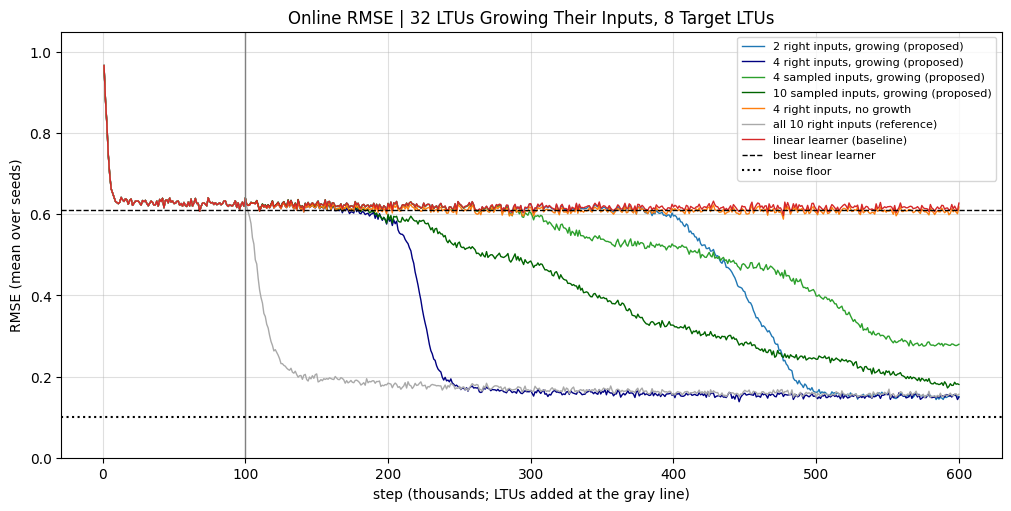

In [6]:
STEPS = (np.arange((LINEAR_STEPS + NUM_STEPS) // WINDOW) + 1) * WINDOW

fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
for (label, config), color in zip(STARTS.items(), ['tab:blue', 'navy', 'tab:green', 'darkgreen', 'tab:orange']):
    ax.plot(STEPS / 1000, rmse[config].mean(0), color=color, lw=1,
            label=label + ('' if not config[2] else ', growing (proposed)'))
ax.plot(STEPS / 1000, rmse[REFERENCE].mean(0), color='darkgray', lw=1, label='all 10 right inputs (reference)')
ax.plot(STEPS / 1000, linear.mean(0), color='tab:red', lw=1, label='linear learner (baseline)')
ax.axvline(LINEAR_STEPS / 1000, color='gray', lw=1)
ax.axhline(LINEAR_RMSE, color='black', ls='--', lw=1, label='best linear learner')
ax.axhline(NOISE_STD, color='black', ls=':', label='noise floor')
ax.set(xlabel='step (thousands; LTUs added at the gray line)', ylabel='RMSE (mean over seeds)', ylim=(0, 1.05),
       title=f'Online RMSE | {N_LTUS} LTUs Growing Their Inputs, {N_TARGETS} Target LTUs')
ax.grid(alpha=0.4)
ax.legend(fontsize=8)
plt.show()

## Results

5 seeds per configuration. The notebook takes about 1 minute.

- **LTUs grow into their target LTU's inputs, and only those.** Starting from 2 right inputs they end with 6 of the 10
  on average, from 4 with 8, adding no wrong input, and both end at the reference's RMSE of 0.15. They reach 0.2 in a
  median 384k and 137k steps after being added (the reference: 36k).
- **Without growth, 4 right inputs do nothing** (0.61): a partial feature barely helps.
- **From sampled inputs growth also works, more slowly**: starting from 10 sampled inputs the LTUs end at 0.19 (4 of 5
  runs below 0.2), from 4 at 0.28. Without growth, sampled inputs found nothing with 8 target LTUs
  (`05_fast_feature_search.ipynb`).